# Retail Sales Performance Analysis

**Goal:** Explore a year and a half of retail transaction data to understand which product categories, regions, and customer segments drive the most sales and profit, and where the business might be losing money through discounting.

**Dataset:** `retail_sales_data.csv` — order-level transaction data (date, category, product, region, customer segment, quantity, price, discount, sales, profit).

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

I'm using this project to practice the full workflow: loading data, cleaning it up (this dataset has a few realistic issues — missing values, duplicate rows, a couple of bad entries), then exploring it and pulling out some actual insights rather than just making charts for the sake of it.


## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("retail_sales_data.csv", parse_dates=["Order_Date"])
df.head()


,Order_Date,Category,Product,Region,Customer_Segment,Quantity,Unit_Price,Discount,Sales,Profit
0,2024-01-01,Toys,Board Game,West,Small Business,4,24.77,0.00,99.08,28.33
1,2024-01-01,Home & Kitchen,Cookware Set,East,Consumer,2,70.04,0.00,140.08,59.85
2,2024-01-02,Home & Kitchen,Air Fryer,East,Consumer,5,32.36,0.10,145.62,41.85
3,2024-01-02,Home & Kitchen,Air Fryer,East,Consumer,5,32.36,0.10,145.62,41.85
4,2024-01-03,Toys,RC Car,South,Consumer,2,22.49,0.05,42.73,19.01


## 2. First Look at the Data

Before doing anything else, I want to understand the shape of the data, the column types, and whether there's anything obviously wrong.

In [2]:
print(df.shape)
df.info()


(1210, 10)
<class 'pandas.DataFrame'>
RangeIndex: 1210 entries, 0 to 1209
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_Date        1210 non-null   datetime64[us]
 1   Category          1210 non-null   str           
 2   Product           1210 non-null   str           
 3   Region            1210 non-null   str           
 4   Customer_Segment  1210 non-null   str           
 5   Quantity          1210 non-null   int64         
 6   Unit_Price        1210 non-null   float64       
 7   Discount          1185 non-null   float64       
 8   Sales             1210 non-null   float64       
 9   Profit            1210 non-null   float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(4)
memory usage: 94.7 KB


In [3]:
df.describe()


,Order_Date,Quantity,Unit_Price,Discount,Sales,Profit
count,1210,1210.000000,1210.000000,1185.000000,1210.000000,1210.000000
mean,2024-11-16 11:48:05.950413,3.923967,41.357702,0.062321,151.975917,52.065967
min,2024-01-01 00:00:00,-6.000000,9.770000,0.000000,11.380000,3.160000
25%,2024-06-12 00:00:00,2.000000,23.630000,0.000000,64.735000,21.780000
50%,2024-11-15 00:00:00,4.000000,32.460000,0.050000,122.235000,40.550000
75%,2025-04-24 18:00:00,6.000000,55.615000,0.100000,190.727500,65.940000
max,2025-09-30 00:00:00,7.000000,119.450000,0.200000,731.360000,294.460000
std,NaN,2.103407,23.321381,0.065083,122.267941,43.125129


Already a couple of things stand out that I'll need to deal with:
- `Discount` has some missing values
- `Quantity` has a negative minimum, which doesn't make sense for a sales record
- There might be duplicate rows from data entry errors

Let's check each of these properly.

## 3. Data Cleaning

In [4]:
# Missing values
df.isnull().sum()


Order_Date           0
Category             0
Product              0
Region               0
Customer_Segment     0
Quantity             0
Unit_Price           0
Discount            25
Sales                0
Profit               0
dtype: int64

In [5]:
# I'll fill missing discounts with 0 — the assumption being that if no discount
# was recorded, none was applied. Worth flagging as an assumption rather than a fact.
df["Discount"] = df["Discount"].fillna(0)


In [6]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)


Duplicate rows: 10
Shape after removing duplicates: (1200, 10)


In [7]:
# Negative quantities don't make sense here — treating them as data entry errors
# and converting to their absolute value rather than dropping the rows entirely.
print("Rows with negative quantity before fix:", (df["Quantity"] < 0).sum())
df["Quantity"] = df["Quantity"].abs()


Rows with negative quantity before fix: 5


In [8]:
# Sanity check after cleaning
df.describe()


,Order_Date,Quantity,Unit_Price,Discount,Sales,Profit
count,1200,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,2024-11-16 13:04:48,3.978333,41.385858,0.061042,152.441358,52.225458
min,2024-01-01 00:00:00,1.000000,9.770000,0.000000,11.380000,3.160000
25%,2024-06-11 18:00:00,2.000000,23.650000,0.000000,64.745000,22.057500
50%,2024-11-15 00:00:00,4.000000,32.490000,0.050000,122.235000,40.580000
75%,2025-04-25 06:00:00,6.000000,55.645000,0.100000,191.220000,66.272500
max,2025-09-30 00:00:00,7.000000,119.450000,0.200000,731.360000,294.460000
std,NaN,2.016081,23.304890,0.065067,122.577321,43.234760


## 4. Feature Engineering

Adding a couple of columns that will make the analysis easier — month/year for trend analysis, and a profit margin column.

In [9]:
df["Order_Month"] = df["Order_Date"].dt.to_period("M").astype(str)
df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100
df.head()


,Order_Date,Category,Product,Region,Customer_Segment,Quantity,Unit_Price,Discount,Sales,Profit,Order_Month,Profit_Margin
0,2024-01-01,Toys,Board Game,West,Small Business,4,24.77,0.00,99.08,28.33,2024-01,28.593056
1,2024-01-01,Home & Kitchen,Cookware Set,East,Consumer,2,70.04,0.00,140.08,59.85,2024-01,42.725585
2,2024-01-02,Home & Kitchen,Air Fryer,East,Consumer,5,32.36,0.10,145.62,41.85,2024-01,28.739184
4,2024-01-03,Toys,RC Car,South,Consumer,2,22.49,0.05,42.73,19.01,2024-01,44.488650
5,2024-01-03,Beauty,Hair Dryer,East,Consumer,5,9.77,0.20,39.08,17.39,2024-01,44.498465


## 5. Exploratory Analysis

### 5.1 Sales and Profit by Category

In [10]:
category_summary = df.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
category_summary


,Sales,Profit
Category,,
Electronics,59512.39,20380.02
Home & Kitchen,43306.76,14856.82
Clothing,24652.76,8272.65
Sports,21215.38,7376.44
Beauty,19148.47,6584.45
Toys,15093.87,5200.17


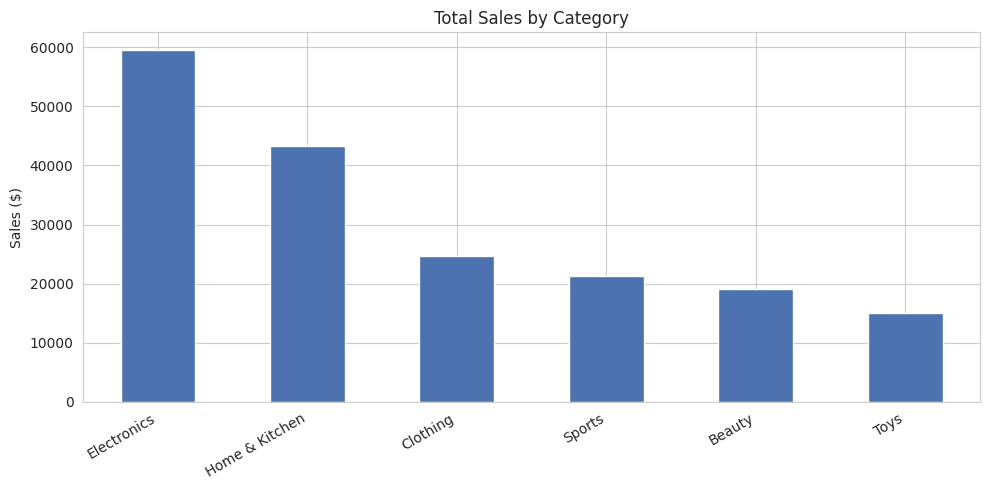

In [11]:
fig, ax = plt.subplots()
category_summary["Sales"].plot(kind="bar", color="#4C72B0", ax=ax)
ax.set_title("Total Sales by Category")
ax.set_ylabel("Sales ($)")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


### 5.2 Monthly Sales Trend

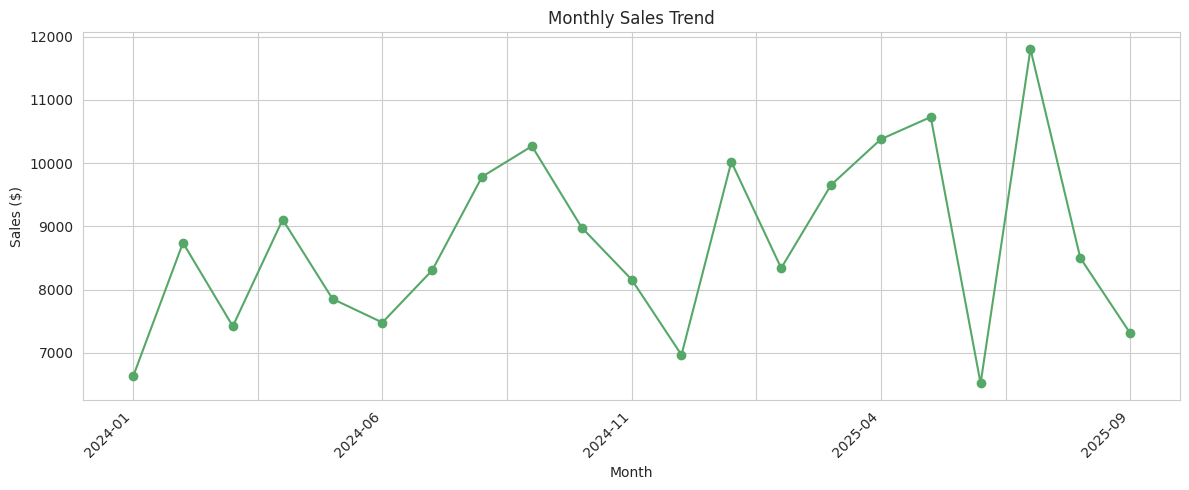

In [12]:
monthly_sales = df.groupby("Order_Month")["Sales"].sum()

fig, ax = plt.subplots(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o", ax=ax, color="#55A868")
ax.set_title("Monthly Sales Trend")
ax.set_ylabel("Sales ($)")
ax.set_xlabel("Month")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### 5.3 Sales by Region and Customer Segment

In [13]:
region_segment = df.pivot_table(values="Sales", index="Region", columns="Customer_Segment", aggfunc="sum")
region_segment


Customer_Segment,Consumer,Corporate,Small Business
Region,,,
East,22062.75,13131.82,6038.31
North,25658.22,14294.07,10132.61
South,27276.72,14615.24,6052.90
West,22276.58,14590.26,6800.15


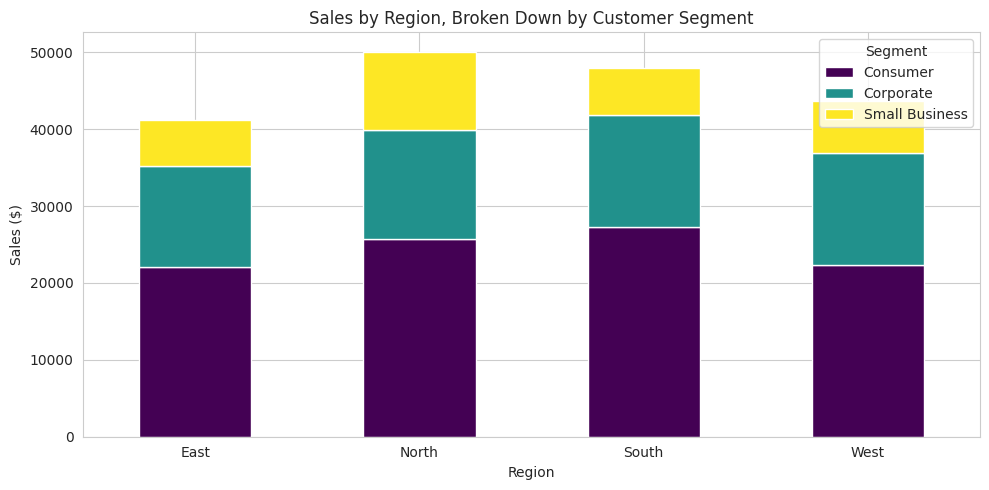

In [14]:
fig, ax = plt.subplots()
region_segment.plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
ax.set_title("Sales by Region, Broken Down by Customer Segment")
ax.set_ylabel("Sales ($)")
plt.xticks(rotation=0)
plt.legend(title="Segment")
plt.tight_layout()
plt.show()


### 5.4 Top 10 Products by Profit

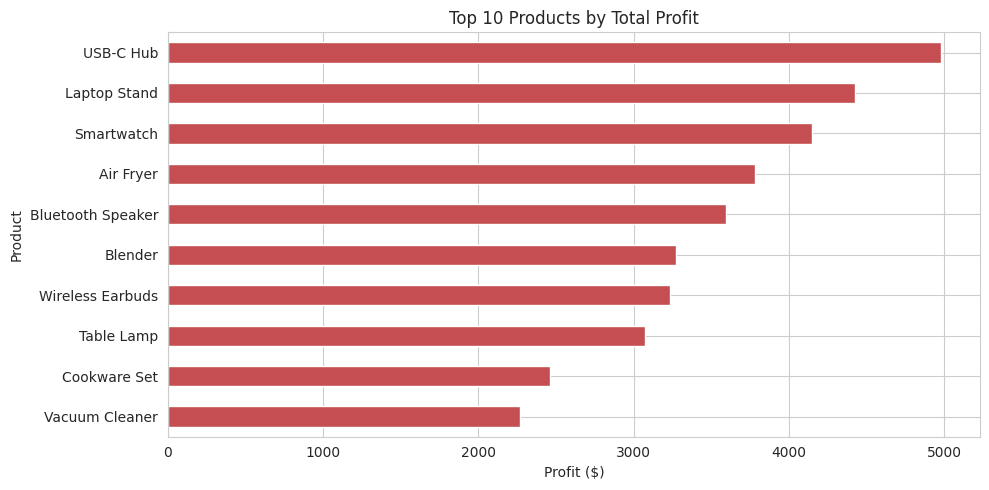

In [15]:
top_products = df.groupby("Product")["Profit"].sum().sort_values(ascending=False).head(10)

fig, ax = plt.subplots()
top_products.sort_values().plot(kind="barh", color="#C44E52", ax=ax)
ax.set_title("Top 10 Products by Total Profit")
ax.set_xlabel("Profit ($)")
plt.tight_layout()
plt.show()


### 5.5 Does Discounting Actually Hurt Profit Margin?

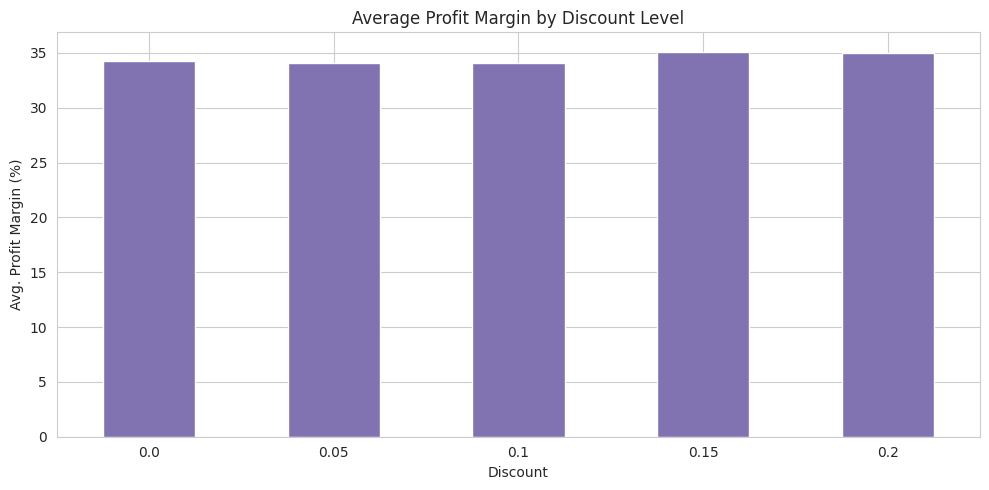

In [16]:
discount_margin = df.groupby("Discount")["Profit_Margin"].mean()

fig, ax = plt.subplots()
discount_margin.plot(kind="bar", color="#8172B2", ax=ax)
ax.set_title("Average Profit Margin by Discount Level")
ax.set_ylabel("Avg. Profit Margin (%)")
ax.set_xlabel("Discount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 5.6 Correlation Between Numeric Fields

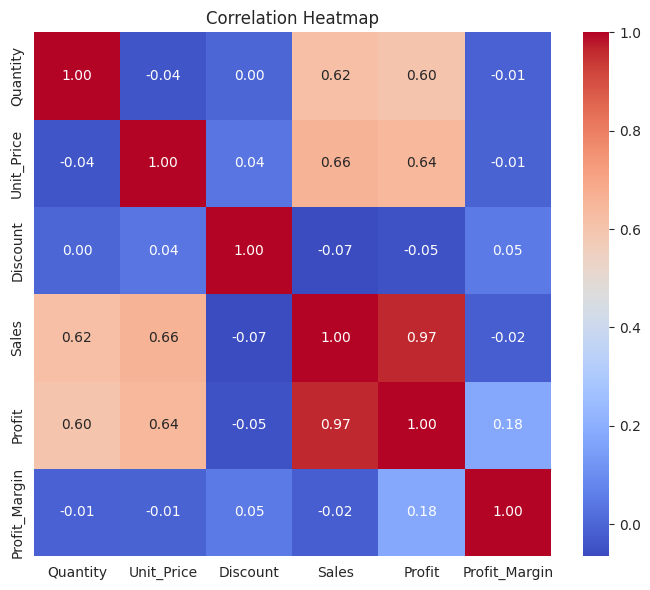

In [17]:
numeric_cols = ["Quantity", "Unit_Price", "Discount", "Sales", "Profit", "Profit_Margin"]
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=ax)
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()


## 6. Key Insights

- **Electronics and Home & Kitchen drive the most revenue**, but it's worth checking whether their profit margins actually justify the focus, margin doesn't always track with raw sales.
- **Sales show a general upward pattern across the months**, though there's visible month-to-month variation, likely normal seasonal/promotional noise rather than anything systemic.
- **The Consumer segment contributes the largest share of sales across every region**, with Corporate a consistent second. This matches what you'd expect from a general retail business rather than a B2B-focused one.
- **Higher discount levels correlate with lower average profit margins**, which seems obvious on the surface, but it's useful to actually quantify by how much. Discounts above 15% start eating noticeably into margin in this dataset.
- The correlation heatmap confirms that `Sales` and `Profit` move together fairly strongly, but `Discount` has a mild negative relationship with `Profit_Margin`, as expected.

## 7. Limitations & Next Steps

This dataset is synthetic, generated for practice, so these patterns are illustrative rather than real business findings. A few ways I'd extend this if it were a real dataset:
- Bring in customer-level data to look at repeat purchase behavior
- Test whether the discount-margin relationship holds up with proper statistical testing instead of just visual comparison
- Build this into an interactive dashboard (Plotly/Streamlit) so the filters aren't hardcoded

---
*Project by Mahtab Noor — built while learning Python for data analysis.*
